In [ ]:
from google.colab import drive
import os

# 1. Подключаем Google Drive
drive.mount('/content/drive')

zip_path = "/content/drive/MyDrive/archive(3).zip"
extract_path = "/content/dataset"

# 2. Проверяем — уже распаковано или нет
if not os.path.exists("/content/dataset/Gano-Cat-Breeds-V1_1"):
    print("Распаковываем архив...")
    os.makedirs(extract_path, exist_ok=True)
    !unzip -q "{zip_path}" -d "{extract_path}"
else:
    print("Архив уже распакован")

# 3. Указываем data_dir
data_dir = "/content/dataset/Gano-Cat-Breeds-V1_1"

# 4. Проверка
print("\nСодержимое data_dir:")
print(os.listdir(data_dir))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Архив уже распакован

Содержимое data_dir:
['Birman', 'Egyptian Mau', 'American Shorthair', 'American Bobtail', 'Bombay', 'Sphynx', 'Ragdoll', 'Tuxedo', 'Russian Blue', 'Persian', '_Readme_.txt', 'Abyssinian', 'British Shorthair', 'Bengal', 'Siamese', 'Maine Coon']


In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms.v2 as T

from IPython.display import clear_output
from PIL import Image
from matplotlib import cm
from time import perf_counter
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
from tqdm import tqdm

warnings.filterwarnings('ignore')

plt.rc('font', size=14)

In [ ]:
# Размер изображений (под ResNet)
IMG_SIZE = 224

# Аугментации (как требует задание)
train_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor()
])

# Для валидации без аугментаций
val_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor()
])

# Загружаем датасет
dataset = ImageFolder(
    root=data_dir,
    transform=train_transforms
)

# Список классов
class_names = dataset.classes

print("Количество классов:", len(class_names))
print("\nКлассы:")
for cls in class_names:
    print(cls)

Количество классов: 15

Классы:
Abyssinian
American Bobtail
American Shorthair
Bengal
Birman
Bombay
British Shorthair
Egyptian Mau
Maine Coon
Persian
Ragdoll
Russian Blue
Siamese
Sphynx
Tuxedo


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

full_train_dataset = ImageFolder(root=data_dir, transform=train_transforms)
full_eval_dataset = ImageFolder(root=data_dir, transform=val_transforms)

class_names = full_train_dataset.classes
num_classes = len(class_names)

indices = list(range(len(full_train_dataset)))
targets = full_train_dataset.targets

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=targets
)

temp_targets = [targets[i] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=temp_targets
)

train_dataset = Subset(full_train_dataset, train_idx)
val_dataset = Subset(full_eval_dataset, val_idx)
test_dataset = Subset(full_eval_dataset, test_idx)

print(f"Train: {len(train_dataset)}")
print(f"Val: {len(val_dataset)}")
print(f"Test: {len(test_dataset)}")

Train: 3937
Val: 844
Test: 844


In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(len(train_loader), len(val_loader), len(test_loader))

124 27 27


In [ ]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


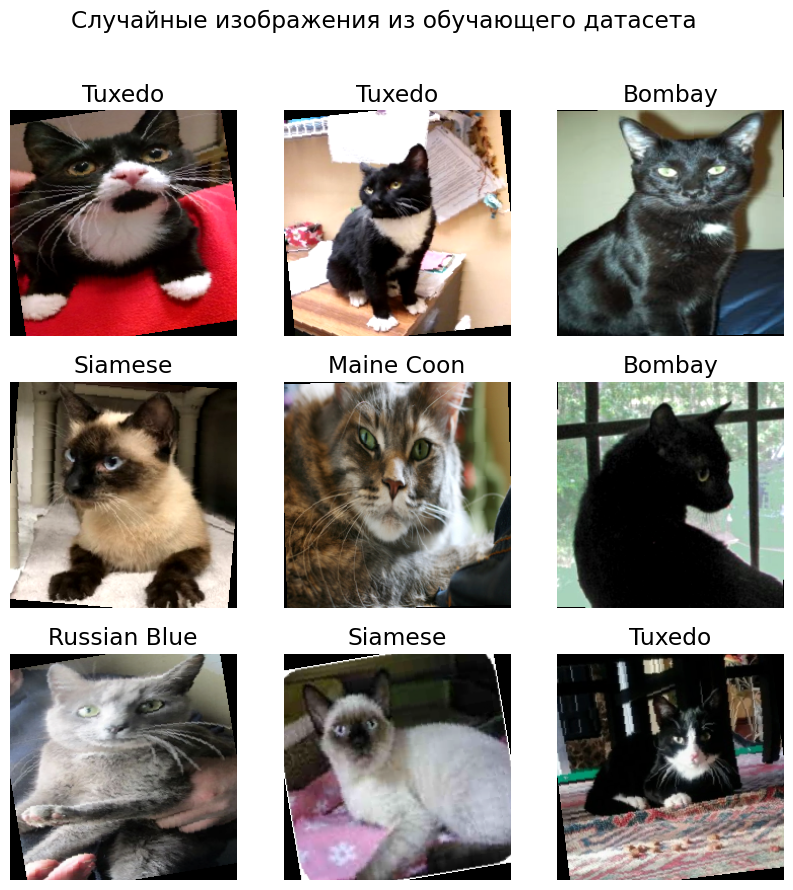

In [ ]:
import random
import matplotlib.pyplot as plt

def show_random_images(dataset, class_names, num_images=9):

    plt.figure(figsize=(10,10))

    for i in range(num_images):

        idx = random.randint(0, len(dataset)-1)

        image, label = dataset[idx]

        img = image.permute(1, 2, 0).numpy()
        img = (img - img.min()) / (img.max() - img.min())

        plt.subplot(3, 3, i+1)
        plt.imshow(img)
        plt.title(class_names[label])
        plt.axis("off")

    plt.suptitle("Случайные изображения из обучающего датасета")
    plt.show()


# показываем примеры
show_random_images(train_dataset, class_names)

In [ ]:
import torch
from torchvision import models
import torch.nn as nn

# 1. Устройство
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

# 2. Модель (пример ResNet50)
# model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
# model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
# 3. Меняем последний слой
# num_features = model.fc.in_features
# model.fc = nn.Linear(num_features, len(class_names))
# num_features = model.classifier[1].in_features
# model.classifier[1] = nn.Linear(num_features, len(class_names))
num_features = model.classifier[2].in_features
model.classifier[2] = nn.Linear(num_features, len(class_names))
# 4. Переносим на устройство
model = model.to(device)

Устройство: cuda
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 164MB/s] 


In [ ]:
# Замораживаем все слои
for param in model.parameters():
    param.requires_grad = False

# Размораживаем только последний слой
if hasattr(model, "fc"):
    for param in model.fc.parameters():
        param.requires_grad = True

elif hasattr(model, "classifier"):
    if isinstance(model.classifier, nn.Sequential):
        for param in model.classifier[-1].parameters():
            param.requires_grad = True
    else:
        for param in model.classifier.parameters():
            param.requires_grad = True

print("Заморозка слоёв выполнена")

Заморозка слоёв выполнена


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3
)

print("Функция потерь и оптимизатор готовы")

Функция потерь и оптимизатор готовы


Epoch 5/5
Train Loss: 0.8865
Train Accuracy: 77.17%
Val Loss: 0.8052
Val Accuracy: 75.36%


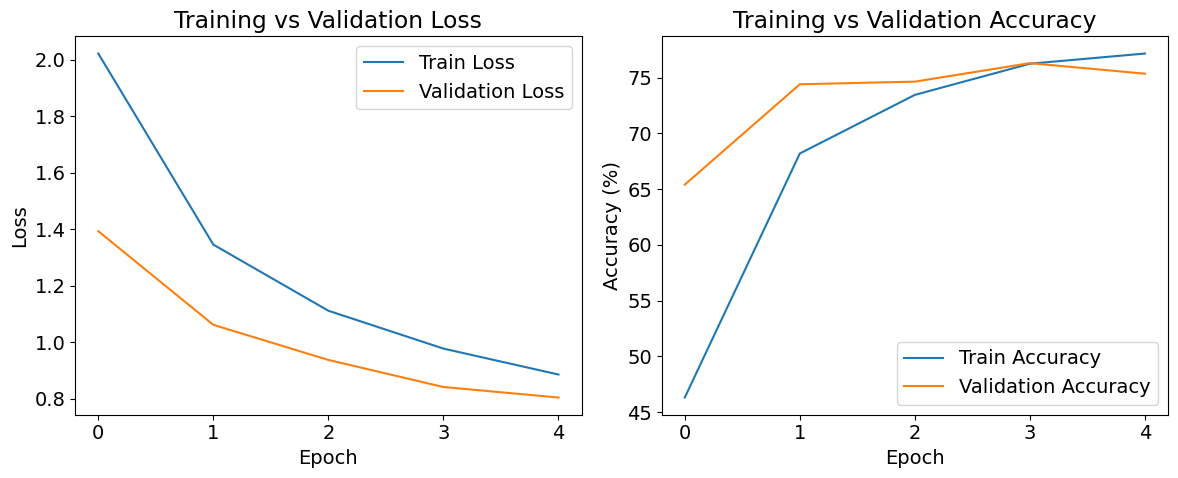

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np
from IPython.display import clear_output

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

num_epochs = 5

for epoch in range(num_epochs):

    # =========================
    # Обучение
    # =========================
    model.train()
    running_loss = 0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct_train / total_train

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # =========================
    # Валидация
    # =========================
    model.eval()
    running_val_loss = 0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = 100 * correct_val / total_val

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    clear_output(wait=True)

    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_accuracy:.2f}%")

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(train_losses, label="Train Loss")
    plt.plot(val_losses, label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(train_accuracies, label="Train Accuracy")
    plt.plot(val_accuracies, label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("Training vs Validation Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()

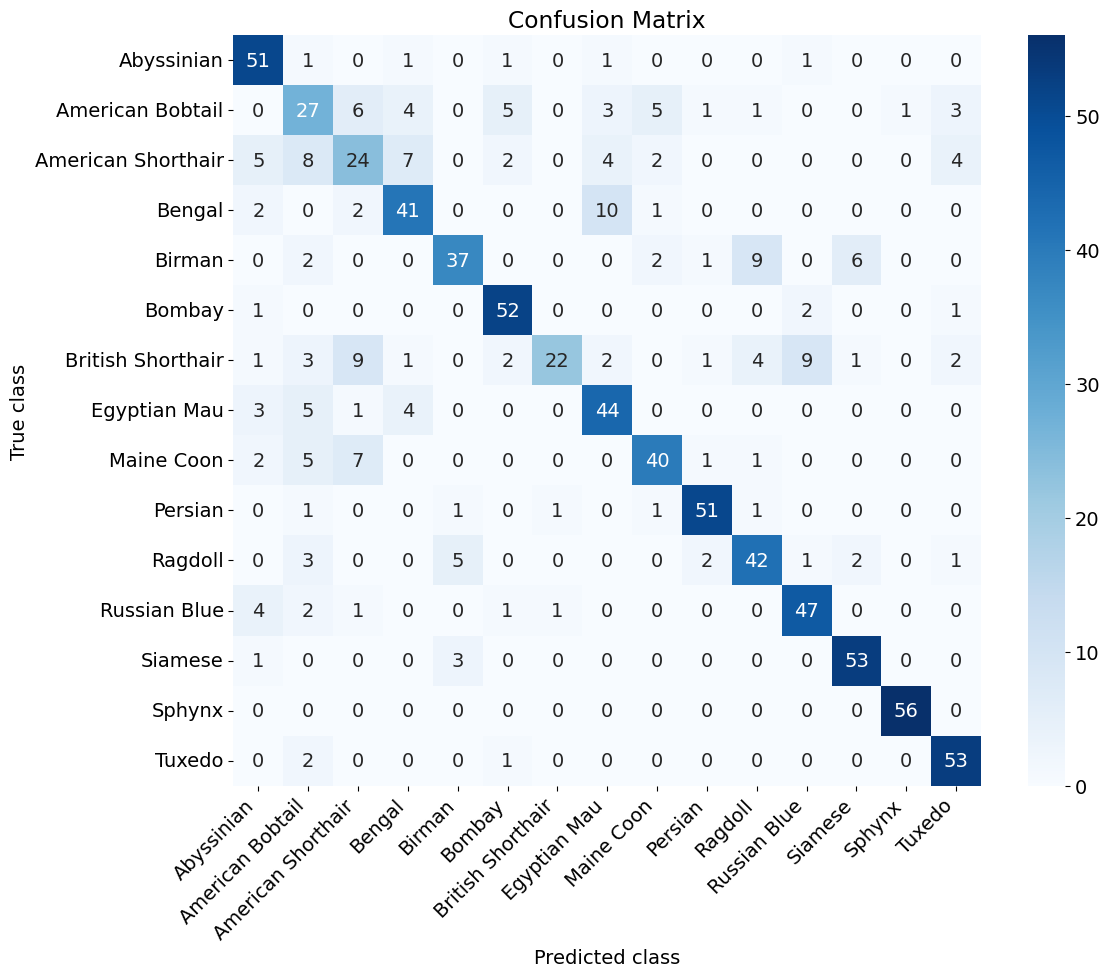

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Строим confusion matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

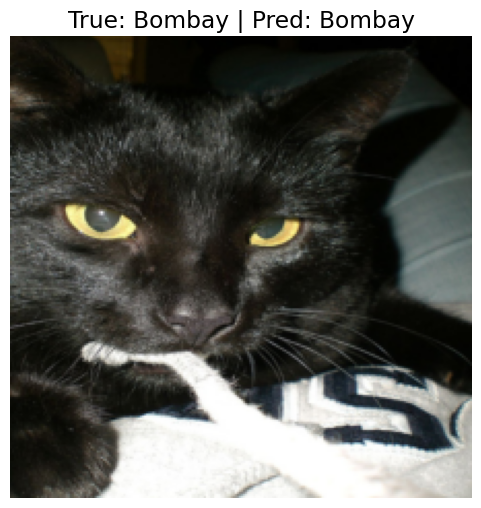

In [ ]:
import random
import matplotlib.pyplot as plt

img, label = test_dataset[random.randint(0, len(test_dataset) - 1)]

model.eval()

with torch.no_grad():
    input_tensor = img.unsqueeze(0).to(device)
    output = model(input_tensor)
    _, predicted = torch.max(output, 1)

img_np = img.permute(1, 2, 0).cpu().numpy()
img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())

plt.figure(figsize=(6, 6))
plt.imshow(img_np)
plt.title(f"True: {class_names[label]} | Pred: {class_names[predicted.item()]}")
plt.axis("off")
plt.show()

In [ ]:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5
)

print("Оптимизатор для fine-tuning готов")

Оптимизатор для fine-tuning готов


In [ ]:
finetune_epochs = 3

finetune_train_losses = []
finetune_val_losses = []
finetune_train_accs = []
finetune_val_accs = []

for epoch in range(finetune_epochs):

    # =========================
    # Обучение
    # =========================
    model.train()
    running_loss = 0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct_train / total_train

    finetune_train_losses.append(train_loss)
    finetune_train_accs.append(train_acc)

    # =========================
    # Валидация
    # =========================
    model.eval()
    running_val_loss = 0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_acc = 100 * correct_val / total_val

    finetune_val_losses.append(val_loss)
    finetune_val_accs.append(val_acc)

    print(f"FineTune Epoch {epoch+1}/{finetune_epochs}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val   Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.2f}%")

FineTune Epoch 1/3
Train Loss: 0.8330 | Train Accuracy: 78.13%
Val   Loss: 0.8023 | Val Accuracy: 75.47%
FineTune Epoch 2/3
Train Loss: 0.8523 | Train Accuracy: 77.88%
Val   Loss: 0.8001 | Val Accuracy: 76.18%
FineTune Epoch 3/3
Train Loss: 0.8255 | Train Accuracy: 78.36%
Val   Loss: 0.7987 | Val Accuracy: 76.66%


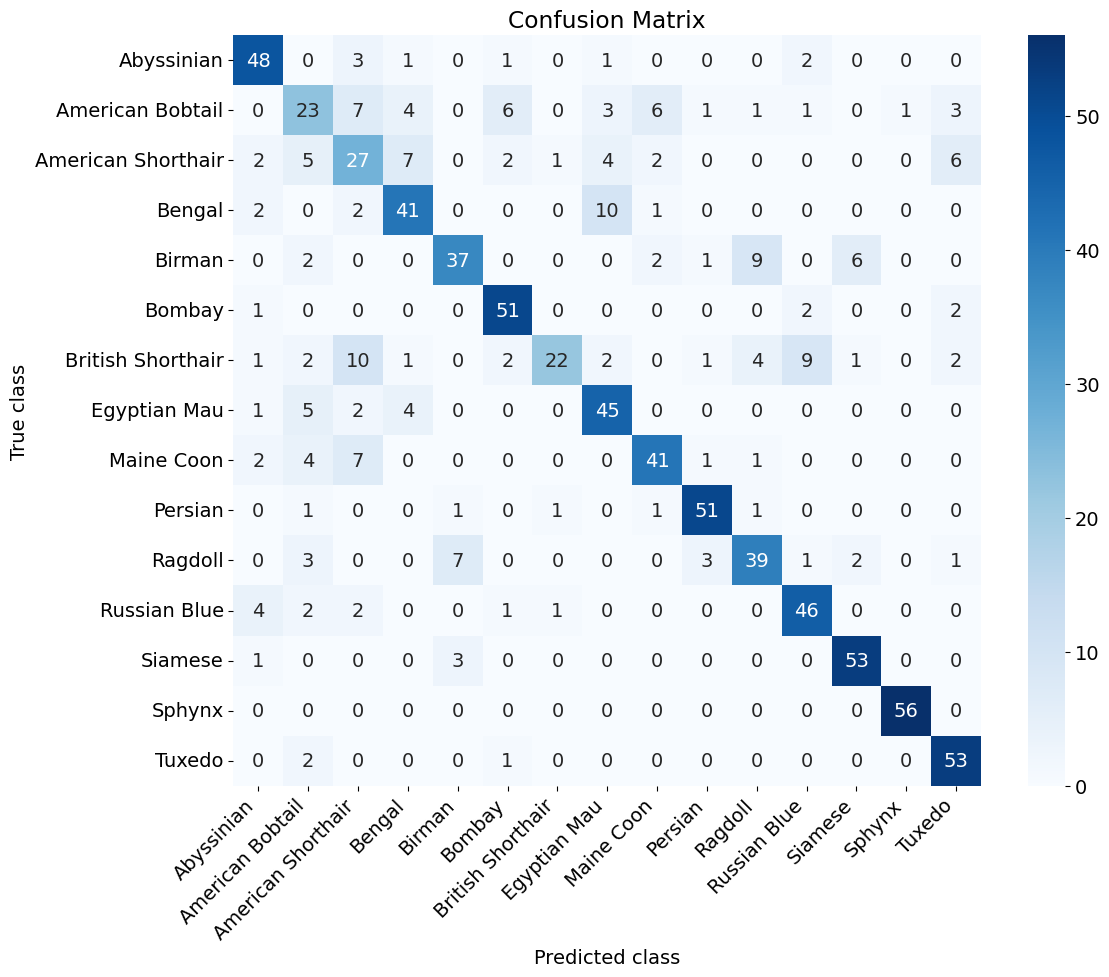

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Смотрим ошибки модели на тестовой выборке
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Строим confusion matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
!pip install -q grad-cam

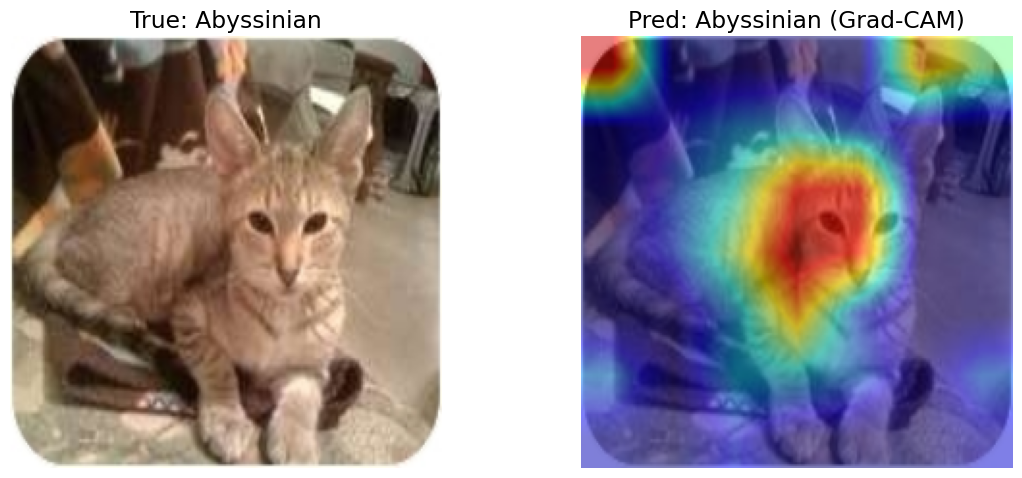

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# На всякий случай включаем градиенты
for param in model.parameters():
    param.requires_grad = True

model.eval()
model.zero_grad()

# Выбери правильный слой:
# Для ResNet18:
# target_layers = [model.layer4[-1].conv2]

# Для ResNet50 вместо строки выше используй:
# target_layers = [model.layer4[-1].conv3]
# target_layers = [model.features[-1]]
target_layers = [model.features[-1][-1].block]

cam = GradCAM(model=model, target_layers=target_layers)

# Берём случайное изображение из тестовой выборки
img, label = test_dataset[random.randint(0, len(test_dataset) - 1)]

input_tensor = img.unsqueeze(0).to(device)
input_tensor.requires_grad_(True)

# Получаем предсказание БЕЗ torch.no_grad()
output = model(input_tensor)
pred_class = output.argmax(dim=1).item()

# Строим Grad-CAM
targets = [ClassifierOutputTarget(pred_class)]
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

# Готовим изображение для отображения
rgb_img = img.permute(1, 2, 0).cpu().numpy()
rgb_img = (rgb_img - rgb_img.min()) / (rgb_img.max() - rgb_img.min())

visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_img)
plt.title(f"True: {class_names[label]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title(f"Pred: {class_names[pred_class]} (Grad-CAM)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# layers = {
#     "Early features": model.conv1,
#     "Middle features": model.layer2,
#     "Deep features": model.layer4
# }
# layers = {
#     "Early features": model.features[0],   # Первая свертка
#     "Middle features": model.features[3],  # Промежуточный блок MBConv
#     "Deep features": model.features[8]     # Финальный блок признаков перед классификатором
# }
layers = {
    "Early features": model.features[0], # Начальная свертка (Downsample)
    "Middle features": model.features[3], # Промежуточный этап
    "Deep features": model.features[7]
}

In [ ]:
feature_maps = {}

def get_features(name):
    def hook(model, input, output):
        feature_maps[name] = output.detach()
    return hook

# Регистрируем hooks
hooks = []

for name, layer in layers.items():
    hooks.append(layer.register_forward_hook(get_features(name)))

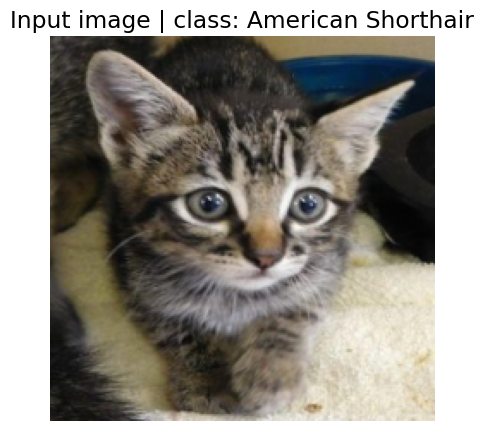

In [ ]:
import random
import matplotlib.pyplot as plt

# Берём случайное изображение из тестовой выборки
img, label = test_dataset[random.randint(0, len(test_dataset) - 1)]

input_tensor = img.unsqueeze(0).to(device)

model.eval()

# Прогоняем через модель, чтобы hooks сохранили признаки
with torch.no_grad():
    _ = model(input_tensor)

# Показываем исходное изображение
img_np = img.permute(1, 2, 0).cpu().numpy()
img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())

plt.figure(figsize=(5, 5))
plt.imshow(img_np)
plt.title(f"Input image | class: {class_names[label]}")
plt.axis("off")
plt.show()

In [ ]:
def visualize_feature_maps(feature_map, title, max_maps=16):
    feature_map = feature_map.squeeze(0)  # убираем batch dimension
    num_maps = min(max_maps, feature_map.shape[0])

    plt.figure(figsize=(12, 6))

    for i in range(num_maps):
        plt.subplot(4, 4, i + 1)
        plt.imshow(feature_map[i].cpu().numpy(), cmap="viridis")
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

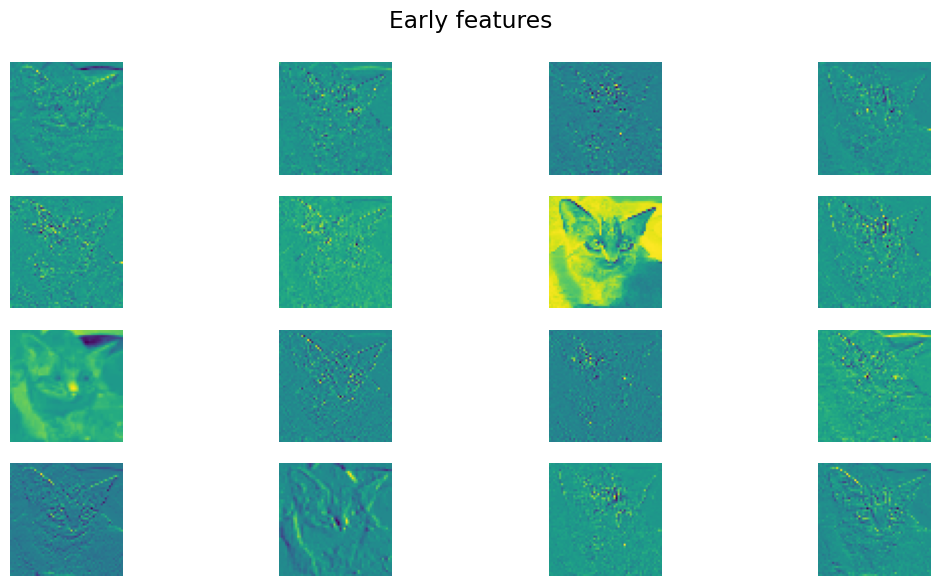

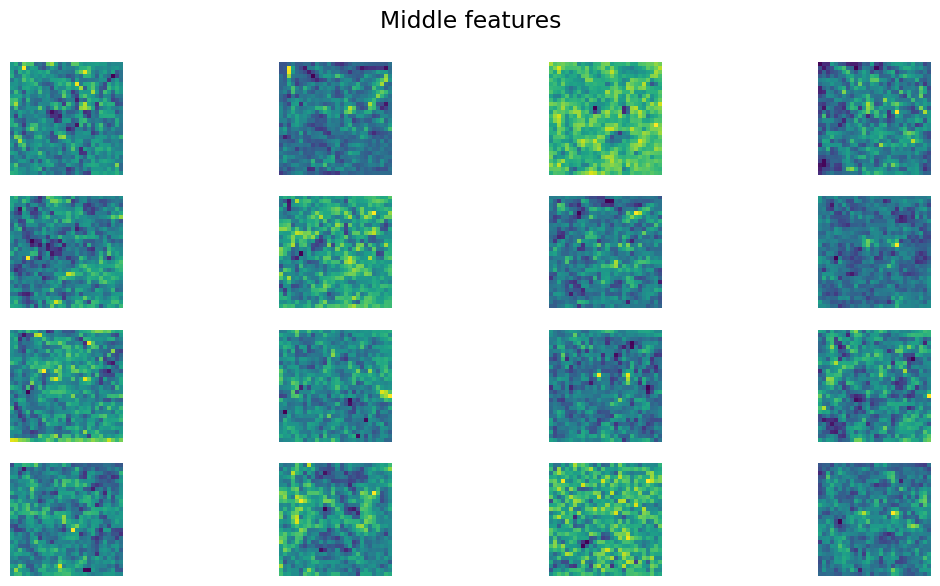

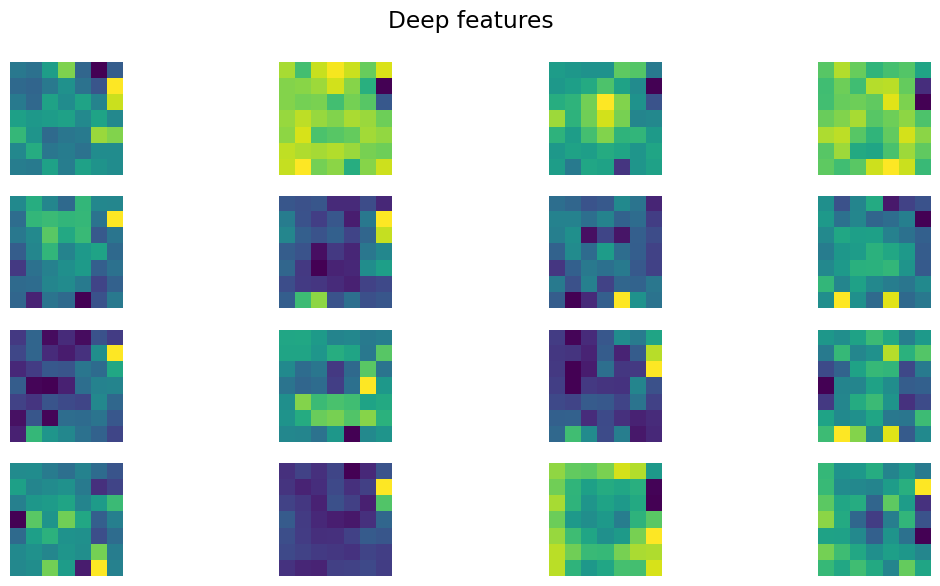

In [ ]:
for name in feature_maps:
    visualize_feature_maps(
        feature_maps[name],
        title=name
    )